# Exploración y verificación de compraventas urbanas con datos enriquecidos.

Grupo 4 · Entrega 2 · 4 de noviembre de 2026

Guillermo Prieto, Juan Sebastián Victoria, Ivette Yvonne Campos y Jecika León.

In [16]:
from pathlib import Path
import numpy as np
import json, urllib.request, urllib.parse
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlencode
from urllib.request import urlopen
import json
from matplotlib.ticker import PercentFormatter

datos = datos = pd.read_csv("datos_modelos_enriquecido_nuevo.csv")
datos.head()

C:\Users\jsvic\AppData\Local\Temp\ipykernel_24780\1355551660.py:11: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  datos = datos = pd.read_csv("datos_modelos_enriquecido_nuevo.csv")


,pk,matricula,fecha_radica_texto,year_radica,orip,divipola,departamento,municipio,tipo_predio_zona,categoria_ruralidad_2024,...,va_proporcion_terciaria,va_total_lag2,va_proporcion_secundaria_lag2,va_proporcion_terciaria_lag2,elic_en_cobertura_lag1,elic_con_registros_lag1,elic_area_nueva_m2_lag1,elic_licencias_nuevas_lag1,elic_area_vivienda_nueva_m2_lag1,elic_unidades_vivienda_nueva_lag1
0,63001-280-000006-00026-00125-2020,280-6,2020-10-09 00:00:00,2020,280,63001,QUINDÍO,ARMENIA,URBANO,Ciudades y aglomeraciones,...,0.822387,4066.695193,0.172048,0.787362,1,1,270866,128,229220,2651
1,63001-280-000009-00019-00125-2018,280-9,2018-04-24 00:00:00,2018,280,63001,QUINDÍO,ARMENIA,URBANO,Ciudades y aglomeraciones,...,0.787362,3674.794267,0.205203,0.754640,1,1,413087,193,371505,3509
2,63001-280-000013-00018-00125-2015,280-13,2015-03-27 00:00:00,2015,280,63001,QUINDÍO,ARMENIA,URBANO,Ciudades y aglomeraciones,...,0.752825,NaN,NaN,NaN,1,1,326086,169,288133,4586
3,63001-280-000013-00021-00125-2022,280-13,07/04/22,2022,280,63001,QUINDÍO,ARMENIA,URBANO,Ciudades y aglomeraciones,...,0.830464,4250.089473,0.129300,0.822387,1,1,195553,139,151253,1398
4,63001-280-000016-00018-00125-2020,280-16,2020-03-04 00:00:00,2020,280,63001,QUINDÍO,ARMENIA,URBANO,Ciudades y aglomeraciones,...,0.822387,4066.695193,0.172048,0.787362,1,1,270866,128,229220,2651


In [17]:
datos.describe()

,year_radica,orip,divipola,num_anotacion,dinamica_2024,cod_natujur,count_a,count_de,predios_nuevos,tiene_valor,...,va_proporcion_terciaria,va_total_lag2,va_proporcion_secundaria_lag2,va_proporcion_terciaria_lag2,elic_en_cobertura_lag1,elic_con_registros_lag1,elic_area_nueva_m2_lag1,elic_licencias_nuevas_lag1,elic_area_vivienda_nueva_m2_lag1,elic_unidades_vivienda_nueva_lag1
count,273586.000000,273586.000000,273586.000000,273586.000000,273586.0,273586.000000,273586.000000,273586.000000,273586.000000,273586.0,...,273586.000000,213052.000000,213052.000000,213052.000000,273586.0,273586.0,2.735860e+05,273586.000000,273586.000000,273586.000000
mean,2019.033642,241.658031,53213.206085,9.945366,1.0,124.999649,1.270471,1.284075,0.000709,1.0,...,0.752004,5282.647145,0.209227,0.748864,1.0,1.0,2.940548e+05,241.221656,244463.302388,2721.774802
std,2.579162,80.295686,20523.997562,8.276972,0.0,0.091768,0.635215,0.964143,0.026620,0.0,...,0.042326,2519.333991,0.046307,0.038914,0.0,0.0,1.568639e+05,147.638750,138275.666170,1537.312690
min,2015.000000,100.000000,17001.000000,1.000000,1.0,101.000000,0.000000,0.000000,0.000000,1.0,...,0.599243,675.860796,0.059461,0.655888,1.0,1.0,5.764000e+03,24.000000,5616.000000,71.000000
25%,2017.000000,280.000000,63001.000000,5.000000,1.0,125.000000,1.000000,1.000000,0.000000,1.0,...,0.721366,3303.918377,0.196721,0.721366,1.0,1.0,1.955530e+05,141.000000,153914.000000,2048.000000
50%,2019.000000,280.000000,63001.000000,8.000000,1.0,125.000000,1.000000,1.000000,0.000000,1.0,...,0.744965,4890.026559,0.218252,0.744965,1.0,1.0,2.736830e+05,175.000000,230695.000000,2514.000000
75%,2021.000000,290.000000,66001.000000,13.000000,1.0,125.000000,1.000000,1.000000,0.000000,1.0,...,0.772474,7481.727654,0.244389,0.768211,1.0,1.0,3.723990e+05,284.000000,307647.000000,3196.000000
max,2023.000000,296.000000,66682.000000,329.000000,1.0,125.000000,44.000000,54.000000,1.000000,1.0,...,0.842189,10414.586923,0.275449,0.842189,1.0,1.0,1.011861e+06,650.000000,916155.000000,9856.000000


In [19]:
# Variación anual del IPC nacional a diciembre, en porcentaje.
ipc_anual_pct = pd.Series({
    2016: 5.75,
    2017: 4.09,
    2018: 3.18,
    2019: 3.80,
    2020: 1.61,
    2021: 5.62,
    2022: 13.12,
    2023: 9.28,
})

anio_base = 2023
factor_por_anio = pd.Series({
    anio: (1 + ipc_anual_pct.loc[anio + 1:anio_base] / 100).prod()
    for anio in range(2015, anio_base + 1)
})

filtro_monetario = (
    datos["valor"].gt(0)
    & datos["tiene_mas_de_un_valor"].eq(0)
)
datos_reales = datos.loc[filtro_monetario].copy()
datos_reales["factor_ipc"] = datos_reales["year_radica"].map(factor_por_anio)

if datos_reales["factor_ipc"].isna().any():
    raise ValueError("Hay años de radicación sin factor de ajuste por IPC.")

datos_reales["valor_cop_dic2023"] = (
    datos_reales["valor"] * datos_reales["factor_ipc"]
)

display(factor_por_anio.rename("factor_a_dic_2023").round(6))

2015    1.564030
2016    1.478988
2017    1.420874
2018    1.377083
2019    1.326669
2020    1.305648
2021    1.236175
2022    1.092800
2023    1.000000
Name: factor_a_dic_2023, dtype: float64

In [23]:
datos_reales.describe()

,year_radica,orip,divipola,num_anotacion,dinamica_2024,cod_natujur,count_a,count_de,predios_nuevos,tiene_valor,...,va_proporcion_secundaria_lag2,va_proporcion_terciaria_lag2,elic_en_cobertura_lag1,elic_con_registros_lag1,elic_area_nueva_m2_lag1,elic_licencias_nuevas_lag1,elic_area_vivienda_nueva_m2_lag1,elic_unidades_vivienda_nueva_lag1,factor_ipc,valor_cop_dic2023
count,273586.000000,273586.000000,273586.000000,273586.000000,273586.0,273586.000000,273586.000000,273586.000000,273586.000000,273586.0,...,213052.000000,213052.000000,273586.0,273586.0,2.735860e+05,273586.000000,273586.000000,273586.000000,273586.000000,2.735860e+05
mean,2019.033642,241.658031,53213.206085,9.945366,1.0,124.999649,1.270471,1.284075,0.000709,1.0,...,0.209227,0.748864,1.0,1.0,2.940548e+05,241.221656,244463.302388,2721.774802,1.309148,2.185604e+08
std,2.579162,80.295686,20523.997562,8.276972,0.0,0.091768,0.635215,0.964143,0.026620,0.0,...,0.046307,0.038914,0.0,0.0,1.568639e+05,147.638750,138275.666170,1537.312690,0.168695,4.915654e+09
min,2015.000000,100.000000,17001.000000,1.000000,1.0,101.000000,0.000000,0.000000,0.000000,1.0,...,0.059461,0.655888,1.0,1.0,5.764000e+03,24.000000,5616.000000,71.000000,1.000000,1.377083e+00
25%,2017.000000,280.000000,63001.000000,5.000000,1.0,125.000000,1.000000,1.000000,0.000000,1.0,...,0.196721,0.721366,1.0,1.0,1.955530e+05,141.000000,153914.000000,2048.000000,1.236175,3.934080e+07
50%,2019.000000,280.000000,63001.000000,8.000000,1.0,125.000000,1.000000,1.000000,0.000000,1.0,...,0.218252,0.744965,1.0,1.0,2.736830e+05,175.000000,230695.000000,2514.000000,1.326669,1.061335e+08
75%,2021.000000,290.000000,66001.000000,13.000000,1.0,125.000000,1.000000,1.000000,0.000000,1.0,...,0.244389,0.768211,1.0,1.0,3.723990e+05,284.000000,307647.000000,3196.000000,1.420874,1.798634e+08
max,2023.000000,296.000000,66682.000000,329.000000,1.0,125.000000,44.000000,54.000000,1.000000,1.0,...,0.275449,0.842189,1.0,1.0,1.011861e+06,650.000000,916155.000000,9856.000000,1.564030,5.681327e+11


In [21]:
claves = ["municipio", "year_radica"]

actividad = (
    datos_reales.groupby(claves)
    .size()
    .rename("compraventas_universo")
    .to_frame()
)

resumen_monetario = datos_reales.groupby(claves).agg(
    registros_monetarios=("valor", "size"),
    mediana_nominal_cop=("valor", "median"),
    mediana_real_cop=("valor_cop_dic2023", "median"),
    q1_real_cop=("valor_cop_dic2023", lambda valores: valores.quantile(0.25)),
    q3_real_cop=("valor_cop_dic2023", lambda valores: valores.quantile(0.75)),
)

tabla_piloto = actividad.join(resumen_monetario).sort_index()
tabla_piloto["riq_real_cop"] = (
    tabla_piloto["q3_real_cop"] - tabla_piloto["q1_real_cop"]
)

# Calcular la variación dentro de cada municipio y en orden cronológico.
for columna, resultado in {
    "compraventas_universo": "variacion_actividad_pct",
    "mediana_real_cop": "variacion_mediana_real_pct",
}.items():
    tabla_piloto[resultado] = (
        tabla_piloto.groupby(level="municipio")[columna]
        .pct_change(fill_method=None)
        .mul(100)
    )

display(tabla_piloto.reset_index().round(2))

,municipio,year_radica,compraventas_universo,registros_monetarios,mediana_nominal_cop,mediana_real_cop,q1_real_cop,q3_real_cop,riq_real_cop,variacion_actividad_pct,variacion_mediana_real_pct
0,ARMENIA,2015,9072,9072,45104500.0,7.054477e+07,27600520.49,1.338604e+08,1.062598e+08,NaN,NaN
1,ARMENIA,2016,10487,10487,48261848.0,7.137868e+07,35643605.27,1.294907e+08,9.384713e+07,15.60,1.18
2,ARMENIA,2017,9478,9478,57500000.0,8.170026e+07,27380242.42,1.522942e+08,1.249139e+08,-9.62,14.46
3,ARMENIA,2018,9697,9697,56086000.0,7.723507e+07,22033324.64,1.391418e+08,1.171085e+08,2.31,-5.47
4,ARMENIA,2019,8612,8612,70000000.0,9.286685e+07,27860056.45,1.526485e+08,1.247884e+08,-11.19,20.24
5,ARMENIA,2020,8521,8521,80987400.0,1.057411e+08,28724265.14,1.881962e+08,1.594719e+08,-1.06,13.86
6,ARMENIA,2021,10942,10942,77500000.0,9.580359e+07,30904384.00,1.658366e+08,1.349322e+08,28.41,-9.40
7,ARMENIA,2022,10079,10079,81200000.0,8.873536e+07,27320000.00,1.562704e+08,1.289504e+08,-7.89,-7.38
8,ARMENIA,2023,9672,9672,108000000.0,1.080000e+08,52268000.00,1.655000e+08,1.132320e+08,-4.04,21.71
9,CALARCÁ,2021,580,580,40000000.0,4.944701e+07,18542630.40,1.024891e+08,8.394645e+07,NaN,NaN


In [24]:
#Ajuste por IPC para valor agregado de la compraventa y valor agregado de dos años antes de la compraventa.
ipc_por_anio = (
    datos_reales[["year_radica", "factor_ipc"]]
    .dropna()
    .drop_duplicates()
    .set_index("year_radica")["factor_ipc"]
)

if not ipc_por_anio.index.is_unique:
    raise ValueError("Hay más de un IPC de diciembre para un mismo año.")

ipc_2023 = ipc_por_anio.loc[2023]

# Valor agregado del mismo año de la compraventa.
ipc_mismo_anio = datos_reales["year_radica"].map(ipc_por_anio)
datos_reales["va_total_ajustado_ipc_2023"] = (
    datos_reales["va_total"] * ipc_2023 / ipc_mismo_anio
)

# Valor agregado de dos años antes de la compraventa.
ipc_anio_rezagado = (datos_reales["year_radica"] - 2).map(ipc_por_anio)
datos_reales["va_total_lag2_ajustado_ipc_2023"] = (
    datos_reales["va_total_lag2"] * ipc_2023 / ipc_anio_rezagado
)

In [26]:
columnas_ipc = [
    "va_total_ajustado_ipc_2023",
    "va_total_lag2_ajustado_ipc_2023",
]

display(datos_reales[["year_radica", "va_total", "va_total_lag2", *columnas_ipc]].head())
print("Valores disponibles por columna:")
print(datos_reales[columnas_ipc].notna().sum())

,year_radica,va_total,va_total_lag2,va_total_ajustado_ipc_2023,va_total_lag2_ajustado_ipc_2023
0,2020,4250.089473,4066.695193,3255.156153,2953.123241
1,2018,4066.695193,3674.794267,2953.123241,2484.668461
2,2015,3303.918377,NaN,2112.439845,NaN
3,2022,5687.054009,4250.089473,5204.112380,3255.156153
4,2020,4250.089473,4066.695193,3255.156153,2953.123241


Valores disponibles por columna:
va_total_ajustado_ipc_2023         273586
va_total_lag2_ajustado_ipc_2023    213052
dtype: int64


In [28]:
#Verificación de los datos de precios para la exploración
precio = pd.to_numeric(datos_reales["valor_cop_dic2023"], errors="coerce")
validos = np.isfinite(precio) & precio.gt(0)

control = pd.Series({
    "Total de registros": len(datos_reales),
    "Faltantes o no numéricos": precio.isna().sum(),
    "Infinitos": np.isinf(precio).sum(),
    "Cero o negativos": (np.isfinite(precio) & precio.le(0)).sum(),
    "Registros incluidos en la exploración": validos.sum(),
})
display(control)

exploracion = datos_reales.loc[validos, ["municipio", "year_radica"]].copy()
exploracion["precio_millones"] = precio.loc[validos] / 1_000_000

Total de registros                       273586
Faltantes o no numéricos                      0
Infinitos                                     0
Cero o negativos                              0
Registros incluidos en la exploración    273586
dtype: int64

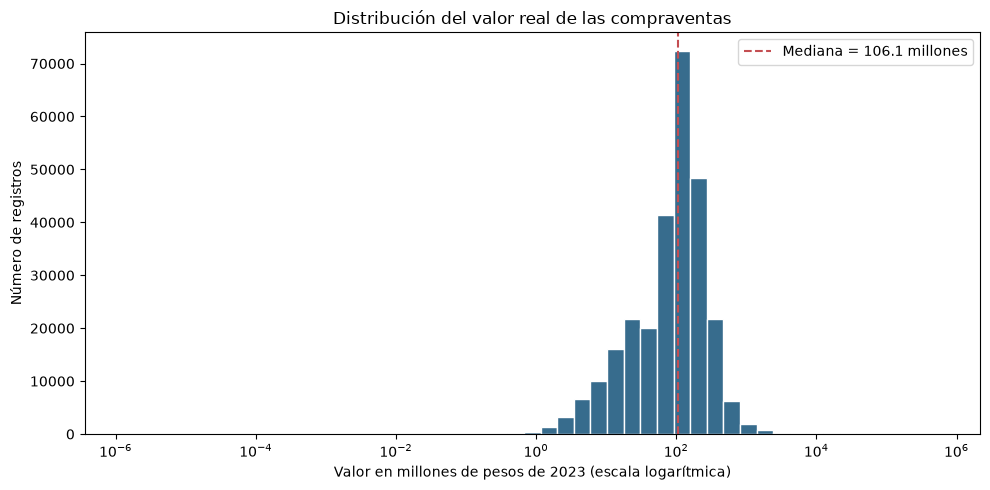

In [29]:
#Graficar la distribución de los precios de compraventa ajustados por IPC
precios = exploracion["precio_millones"]
bins = np.geomspace(precios.min(), precios.max(), 50)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(precios, bins=bins, color="#376C8D", edgecolor="white")
ax.set_xscale("log")
ax.axvline(
    precios.median(),
    color="#C44E52",
    linestyle="--",
    label=f"Mediana = {precios.median():,.1f} millones",
)
ax.set(
    title="Distribución del valor real de las compraventas",
    xlabel="Valor en millones de pesos de 2023 (escala logarítmica)",
    ylabel="Número de registros",
)
ax.legend()
plt.tight_layout()
plt.show()

In [30]:
#Percentiles de los precios de compraventa ajustados por IPC por municipio
por_municipio = exploracion.groupby("municipio")["precio_millones"]

resumen = por_municipio.quantile([0.25, 0.50, 0.75, 0.99]).unstack()
resumen.columns = ["p25", "mediana", "p75", "p99"]
resumen.insert(0, "registros", por_municipio.size())
resumen["rango_intercuartilico"] = resumen["p75"] - resumen["p25"]
resumen["maximo"] = por_municipio.max()

display(resumen.sort_values("mediana", ascending=False).round(2))

,registros,p25,mediana,p75,p99,rango_intercuartilico,maximo
municipio,,,,,,,
MANIZALES,66295,49.25,130.82,219.54,1127.67,170.29,568132.72
PEREIRA,61181,60.79,124.72,208.54,1719.20,147.75,537090.40
DOSQUEBRADAS,42713,45.10,103.28,148.00,406.54,102.90,168132.84
ARMENIA,86560,30.00,88.21,154.23,702.93,124.23,19725.66
CALARCÁ,2565,18.54,60.00,109.28,471.62,90.74,1750.67
SANTA ROSA DE CABAL,14272,18.59,60.00,125.12,1280.68,106.53,126196.55


In [33]:
#Revision de maximos y minimos en la base original
columnas = [
    "municipio", "year_radica", "num_anotacion",
    "valor", "factor_ipc", "valor_cop_dic2023",
]

revision = datos_reales.loc[validos, columnas].copy()
revision["precio_millones"] = precio.loc[validos] / 1_000_000

print("10 registros de menor valor")
display(revision.nsmallest(10, "precio_millones"))

print("10 registros de mayor valor")
display(revision.nlargest(10, "precio_millones"))

10 registros de menor valor


,municipio,year_radica,num_anotacion,valor,factor_ipc,valor_cop_dic2023,precio_millones
131843,MANIZALES,2018,23,1.0,1.377083,1.377083,0.000001
165019,MANIZALES,2017,5,1.0,1.420874,1.420874,0.000001
123705,DOSQUEBRADAS,2020,5,2.0,1.305648,2.611297,0.000003
123802,DOSQUEBRADAS,2020,5,2.0,1.305648,2.611297,0.000003
264389,SANTA ROSA DE CABAL,2015,5,4.3,1.564030,6.725327,0.000007
107647,DOSQUEBRADAS,2017,6,5.0,1.420874,7.104370,0.000007
109013,DOSQUEBRADAS,2017,5,5.0,1.420874,7.104370,0.000007
174380,MANIZALES,2016,1,20.0,1.478988,29.579755,0.000030
174381,MANIZALES,2016,2,28.0,1.478988,41.411658,0.000041
101463,DOSQUEBRADAS,2017,10,35.0,1.420874,49.730591,0.000050


10 registros de mayor valor


,municipio,year_radica,num_anotacion,valor,factor_ipc,valor_cop_dic2023,precio_millones
174054,MANIZALES,2016,3,3.841362e+11,1.478988,5.681327e+11,568132.718328
174111,MANIZALES,2016,3,3.841362e+11,1.478988,5.681327e+11,568132.718328
174277,MANIZALES,2016,3,3.841362e+11,1.478988,5.681327e+11,568132.718328
221260,PEREIRA,2017,5,3.780000e+11,1.420874,5.370904e+11,537090.401979
221261,PEREIRA,2017,5,3.780000e+11,1.420874,5.370904e+11,537090.401979
221262,PEREIRA,2017,5,3.780000e+11,1.420874,5.370904e+11,537090.401979
221263,PEREIRA,2017,5,3.780000e+11,1.420874,5.370904e+11,537090.401979
221264,PEREIRA,2017,5,3.780000e+11,1.420874,5.370904e+11,537090.401979
221265,PEREIRA,2017,5,3.780000e+11,1.420874,5.370904e+11,537090.401979
221266,PEREIRA,2017,5,3.780000e+11,1.420874,5.370904e+11,537090.401979


In [34]:
precio = revision["precio_millones"]
por_municipio = revision.groupby("municipio")["precio_millones"]

revision_colas = revision.assign(
    debajo_p01=precio.lt(por_municipio.transform("quantile", q=0.01)),
    encima_p99=precio.gt(por_municipio.transform("quantile", q=0.99)),
    valor_nominal_hasta_35=revision["valor"].le(35),
)

resumen_colas = revision_colas.groupby("municipio").agg(
    registros=("precio_millones", "size"),
    debajo_p01=("debajo_p01", "sum"),
    encima_p99=("encima_p99", "sum"),
    valor_nominal_hasta_35=("valor_nominal_hasta_35", "sum"),
)

display(resumen_colas)

,registros,debajo_p01,encima_p99,valor_nominal_hasta_35
municipio,,,,
ARMENIA,86560,865,800,0
CALARCÁ,2565,26,25,0
DOSQUEBRADAS,42713,424,427,5
MANIZALES,66295,663,661,4
PEREIRA,61181,610,596,0
SANTA ROSA DE CABAL,14272,143,35,1


In [35]:
display(
    datos[["cod_municipio", "municipio"]]
    .drop_duplicates()
    .sort_values("cod_municipio")
    .reset_index(drop=True)
)

,cod_municipio,municipio
0,17001,MANIZALES
1,63001,ARMENIA
2,63130,CALARCÁ
3,66001,PEREIRA
4,66170,DOSQUEBRADAS
5,66682,SANTA ROSA DE CABAL


In [36]:
santa_rosa = revision.loc[
    revision["municipio"].eq("SANTA ROSA DE CABAL"), "precio_millones"
]
p99 = santa_rosa.quantile(0.99)

display(pd.Series({
    "P99 en millones de pesos de 2023": p99,
    "Registros por encima del P99": santa_rosa.gt(p99).sum(),
    "Registros exactamente en el P99": santa_rosa.eq(p99).sum(),
}))

P99 en millones de pesos de 2023    1280.677673
Registros por encima del P99          35.000000
Registros exactamente en el P99      183.000000
dtype: float64

# Distribución del valor real de las compraventas

Se exploró la distribución del valor_real_2023 para 273.734 registros de seis municipios entre 2015 y 2023. los montos del histrograma y de la tabla están expresados en millones de pesos de diciembre de 2023.

## Proceso
1. Se verificó que el valor real fuera numérico, finito y mayor que cero. Todos los registros cumplieron.
2. Se graficó la distribución en escala logarítmica y se marcó la mediana general.
3. se calcularon el p25, la mediana p75, el p99, el rango intercuartílico y el máximo por municipio.
4. Se revisaron los diez registros de menor valor real y los diez de mayor valor real, comparándolos con suis montos nominales en valor. También se contaron los registros por debajo del p01 y por encima del p99 de cada municipio.

## Hallazgos
1. La mediana general fue de 106,14 millones de pesos de 2023. Manizales presentó la mediana más alta (130,83 millones), seguido de pereira (124,73 millones). Pereira presentó el p99 más alto (1.719,34 millones).
2. Hubo 2.732 registros por debajo del p01 y 2.544 por encima del p99 de sus respectivos municipios.
3. Los diez registros de menor valor real tenían montos nominales entre 1 y 35 pesos. Esos montos ya estaban en la fuente antes del ajuste por IPC.
4. Entre los registros de mayor valor se repitieron montos nominales de aproximadamente 384 mil millones de pesos en Manizales y 378 mil millones en Pereira. Se requiere verificar el folio de matrícula y el número de antación para determinar si las coincidencias corresponden al mismo acto.
5. En Santa Rosa de Cabal, el p99 fue de 1.208,66 millones de pesos de 2023. Hubo 183 registros exactamente en ese valor y 35 por encima. Los empates explican por qué solo el 0,25% superó estrictamente el p99.

## Tratamiento de valores extremos
Se conservaron todos los registros en esta etapa. Los percentiles y el umbral de 35 pesos se usaron apra identificar casos que requieren revisión. La verificación de los montos atípicos y de las coincidencias queda pendiente en la fuente.

# Evolución anual por municipio

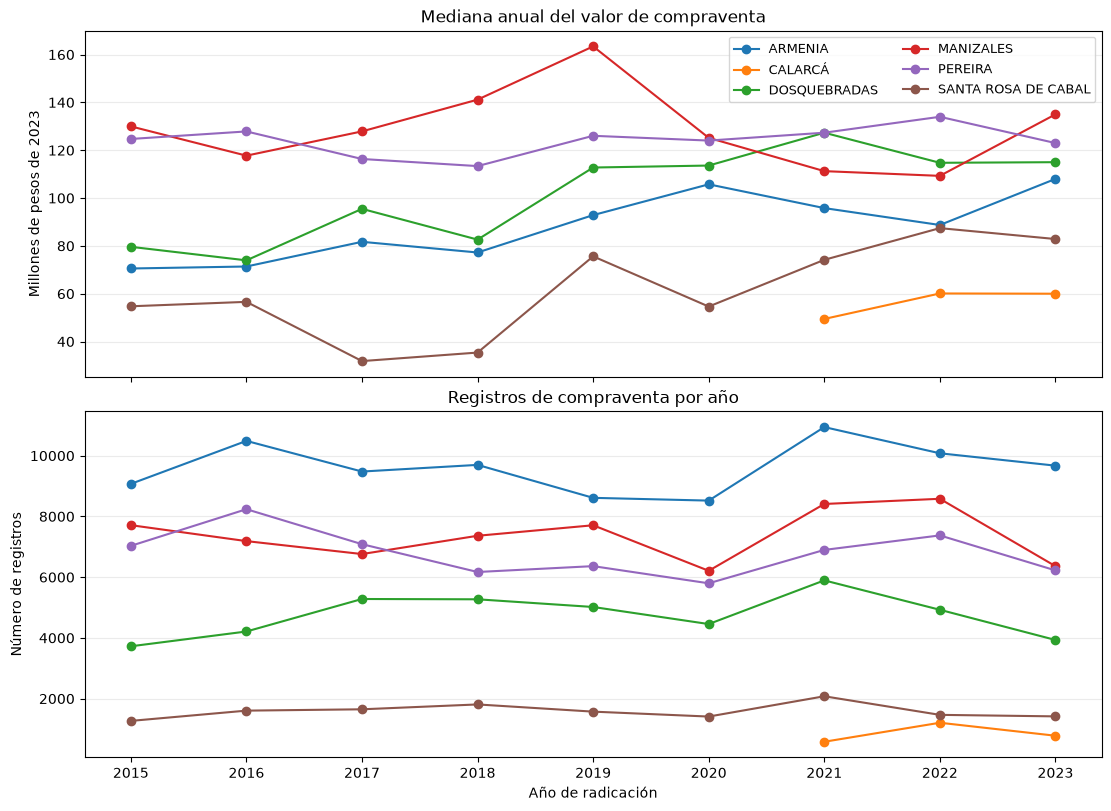

In [37]:
resumen_anual = (
    revision.groupby(["municipio", "year_radica"], as_index=False)
    .agg(
        mediana_millones=("precio_millones", "median"),
        registros=("precio_millones", "size"),
    )
    .sort_values(["municipio", "year_radica"])
)

anios = range(
    int(resumen_anual["year_radica"].min()),
    int(resumen_anual["year_radica"].max()) + 1,
)

fig, (ax_precio, ax_registros) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True, layout="constrained"
)

for municipio, grupo in resumen_anual.groupby("municipio"):
    serie = grupo.set_index("year_radica").reindex(anios)
    linea, = ax_precio.plot(
        serie.index, serie["mediana_millones"], marker="o", label=municipio
    )
    ax_registros.plot(
        serie.index, serie["registros"], marker="o", color=linea.get_color()
    )

ax_precio.set(
    title="Mediana anual del valor de compraventa",
    ylabel="Millones de pesos de 2023",
)
ax_registros.set(
    title="Registros de compraventa por año",
    ylabel="Número de registros",
    xlabel="Año de radicación",
    xticks=list(anios),
)
ax_precio.legend(ncol=2, fontsize=9)

for ax in (ax_precio, ax_registros):
    ax.grid(axis="y", alpha=0.25)

plt.show()

Se agruparon los registros por municipio y año. Para cada grupo se calculó la mediana del valor de compraventa en millones de pesos de 2023 y el número de registros en la base. Los años sin observaciones se dejan como huecos en las gráficas.

## Hallazgos
1. Manizales alcanzó la mediana anual más alta de todas, cerca de 160 millones en 2019. Luego bajó a unos 110 millones en 2022 y repuntó a 135 millones en 2023. En ese último año subió la mediana y cayó el número de registros.
2. Perreira mantuvo la mediana entre aproximadamente 115 y 135 millones. En ese ultimo año subió la mediana y cayó el número de registros.
3. Armenia tuvo el mayor número de registros de cada año del periodo. Su mediana pasó de cerca de 70 millones en 2015 a 108 millones en 2023. Dosquebradas alcanzó su mediana más alta en 2021, alrededor de 125 millones.
4. Santa Rosa de Cabal pasó de una mediana cercana a 32 millones en 2017 a 87 millones en 2022. Calarcá solo tiene registros en la base desde 2021. Su mediana subió de unos 50 millones en 2021 a 60 millones en 2022 donde se mantuvo hasta 2023.

La mediana desribe el valor de las compraventas registradas en cada municipio y año. Puede variar tanto por cambios en los precios como por cambios en el tipo de inmuebles vendidos. El número de registros ayuda a contextualizar cada mediana y se refierea la cobertura de la base actualizada.

# Variables complementarias del DANE

In [39]:
claves = ["municipio", "year_radica"]
variables = [
    "va_total_ajustado_ipc_2023",
    "elic_unidades_vivienda_nueva_lag1",
    "proporcion_cabecera",
    "crecimiento_poblacion",
]

variacion = datos_reales.groupby(claves)[variables].nunique(dropna=False)
conflictos = variacion.gt(1).any(axis=1)

if conflictos.any():
    display(variacion.loc[conflictos])
    raise ValueError("Hay valores DANE distintos para un mismo municipio y año.")

dane_anual = (
    datos_reales[claves + variables]
    .drop_duplicates(subset=claves)
    .sort_values(claves)
)

print(f"Combinaciones municipio-año: {len(dane_anual)}")
display(dane_anual.head(20))

Combinaciones municipio-año: 48


,municipio,year_radica,va_total_ajustado_ipc_2023,elic_unidades_vivienda_nueva_lag1,proporcion_cabecera,crecimiento_poblacion
2,ARMENIA,2015,2112.439845,4586,0.973651,0.005415
10,ARMENIA,2016,2484.668461,2983,0.973308,0.007368
8,ARMENIA,2017,2754.915699,1535,0.973298,0.008809
1,ARMENIA,2018,2953.123241,3509,0.973039,0.012033
15,ARMENIA,2019,3299.064882,3196,0.973379,0.006887
0,ARMENIA,2020,3255.156153,2651,0.973782,0.007549
5,ARMENIA,2021,3955.770934,2055,0.973615,0.008608
3,ARMENIA,2022,5204.112380,1398,0.973484,0.005049
12,ARMENIA,2023,6394.664340,1056,0.973340,0.002382
86576,CALARCÁ,2021,693.969164,170,0.775358,0.004958


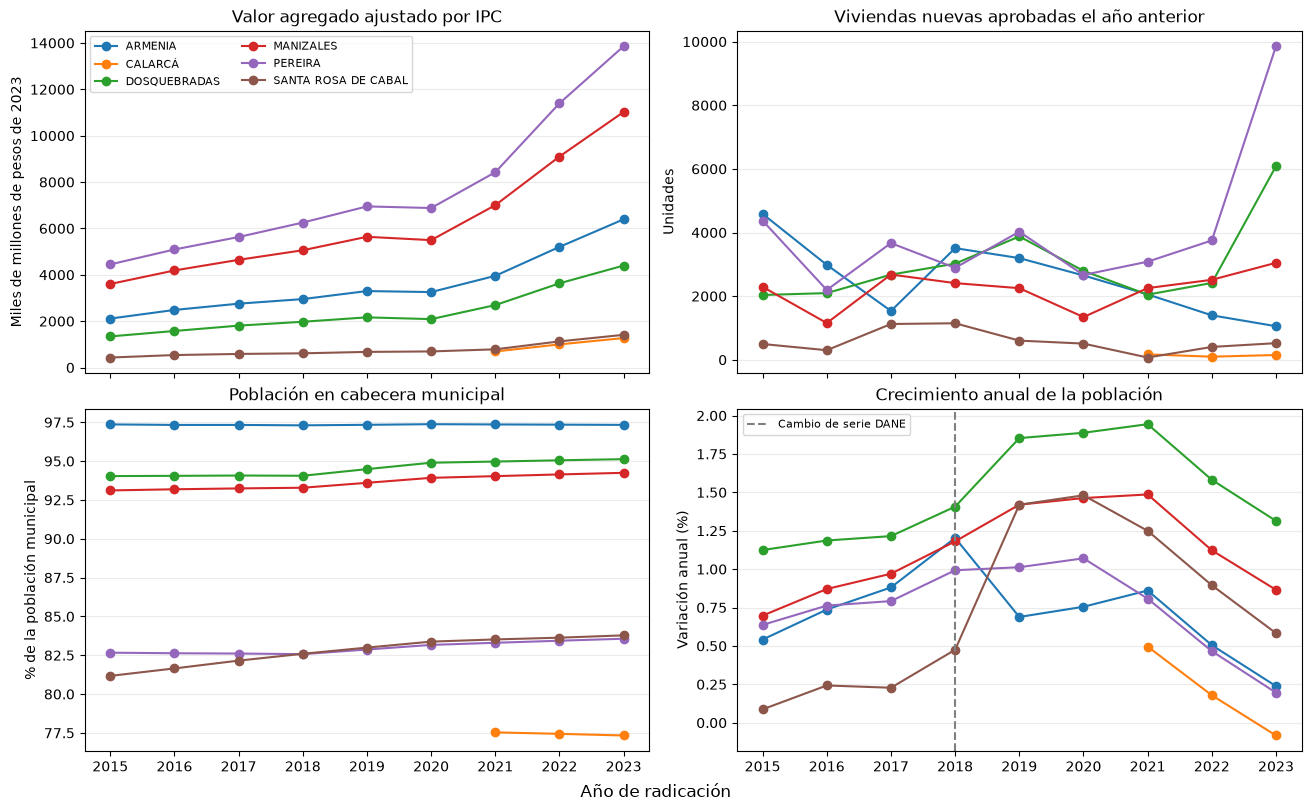

In [40]:
graficos = [
    ("va_total_ajustado_ipc_2023", "Valor agregado ajustado por IPC",
     "Miles de millones de pesos de 2023", 1),
    ("elic_unidades_vivienda_nueva_lag1", "Viviendas nuevas aprobadas el año anterior",
     "Unidades", 1),
    ("proporcion_cabecera", "Población en cabecera municipal",
     "% de la población municipal", 100),
    ("crecimiento_poblacion", "Crecimiento anual de la población",
     "Variación anual (%)", 100),
]

anios = range(
    int(dane_anual["year_radica"].min()),
    int(dane_anual["year_radica"].max()) + 1,
)

fig, ejes = plt.subplots(
    2, 2, figsize=(13, 8), sharex=True, layout="constrained"
)

for ax, (columna, titulo, unidad, escala) in zip(ejes.flat, graficos):
    for municipio, grupo in dane_anual.groupby("municipio"):
        serie = grupo.set_index("year_radica")[columna].reindex(anios)
        ax.plot(serie.index, serie * escala, marker="o", label=municipio)

    ax.set(title=titulo, ylabel=unidad, xticks=list(anios))
    ax.grid(axis="y", alpha=0.25)

ejes[0, 0].legend(fontsize=8, ncol=2)
ejes[1, 1].axvline(2018, color="gray", linestyle="--", label="Cambio de serie DANE")
ejes[1, 1].legend(handles=[ejes[1, 1].lines[-1]], fontsize=8)
fig.supxlabel("Año de radicación")
plt.show()

Se construyó una tabla con 48 combinaciones de municipio-año. Se verificó que cada variable tuviera un único valor por combinación, ya que las cifras municipales se repiten en todas las compraventas del mismo municipio y año.

## Hallazgos
1. Valor agregado ajustado por IPC. Pereira y Manizales registraron los niveles más altos durante todo el período. En ambos municipios se observa una caida en 2020 y una recuperación en 2021. El ajuste por IPC expresa los montos en terminos del poder adquisitivo de diciembre de 2023.
2. Vivienda nueva aprobada. La serie fluctúa más que las demás variables. En el punto de 2023, Pereira y Dosquebradas alcanzan aproximadamente 10.000 y 6.000 unidades respectivamente. Como la variable tiene un año de rezago, esas cifras corresponden a aprobaciones del año 2022.
3. Población en cabecera. La proporción distingue a los municipios y cambia poco dentrod e cada uno. Armenia se mantiene cerca del 97%. Pereira y Santa Rosa de Cabal terminan cerca del 84% y Calarcá se sitúa alrededor del 77,5%.
4. Crecimiento poblacionale. Dosquebradas presenta la mayor tasa anual en todos los años graficados y se acerca al 2% en 2021. En Calarcá, la tasa desciende hasta un valor ligeramente negativo en 2023. La línea punteada vertical en 2018 señala el cambio de serie del CANE, que debe tenerse en cuebnta al interpretar la variación frente a 2017.

# Composición de la población por edades

In [41]:
claves = ["municipio", "year_radica"]
edades = [f"poblacion_edad_{edad}" for edad in range(85)]
edades.append("poblacion_edad_85_mas")
columnas = ["poblacion_total", *edades]

edades_anual = datos[claves + columnas].drop_duplicates().copy()

if edades_anual.duplicated(claves).any():
    raise ValueError("Hay conteos de población distintos para un mismo municipio y año.")

total = edades_anual["poblacion_total"]
conteos = edades_anual[edades]

if (
    total.isna().any()
    or total.le(0).any()
    or conteos.isna().any().any()
    or conteos.lt(0).any().any()
    or not conteos.sum(axis=1).eq(total).all()
):
    raise ValueError("Hay conteos faltantes o inconsistentes con la población total.")

grupos_edad = {
    "0–17": edades[0:18],
    "18–24": edades[18:25],
    "25–44": edades[25:45],
    "45–64": edades[45:65],
    "65+": edades[65:],
}

for grupo, columnas_edad in grupos_edad.items():
    edades_anual[grupo] = edades_anual[columnas_edad].sum(axis=1) / total

edades_anual = edades_anual[claves + list(grupos_edad)].sort_values(claves)
assert np.allclose(edades_anual[list(grupos_edad)].sum(axis=1), 1)

print(f"Combinaciones municipio-año: {len(edades_anual)}")
display(edades_anual.head(10).style.format({
    grupo: "{:.1%}" for grupo in grupos_edad
}))

Combinaciones municipio-año: 48


,municipio,year_radica,0–17,18–24,25–44,45–64,65+
2,ARMENIA,2015,23.5%,12.0%,27.9%,25.2%,11.4%
10,ARMENIA,2016,23.0%,11.9%,28.0%,25.3%,11.8%
8,ARMENIA,2017,22.5%,11.7%,28.2%,25.4%,12.3%
1,ARMENIA,2018,23.4%,11.1%,27.2%,24.8%,13.5%
15,ARMENIA,2019,23.0%,11.1%,27.5%,24.6%,13.7%
0,ARMENIA,2020,22.6%,11.1%,27.9%,24.5%,14.0%
5,ARMENIA,2021,22.2%,11.1%,28.2%,24.3%,14.2%
3,ARMENIA,2022,21.8%,11.0%,28.5%,24.3%,14.4%
12,ARMENIA,2023,21.5%,10.9%,28.7%,24.3%,14.7%
86576,CALARCÁ,2021,23.6%,11.3%,27.5%,23.7%,13.9%


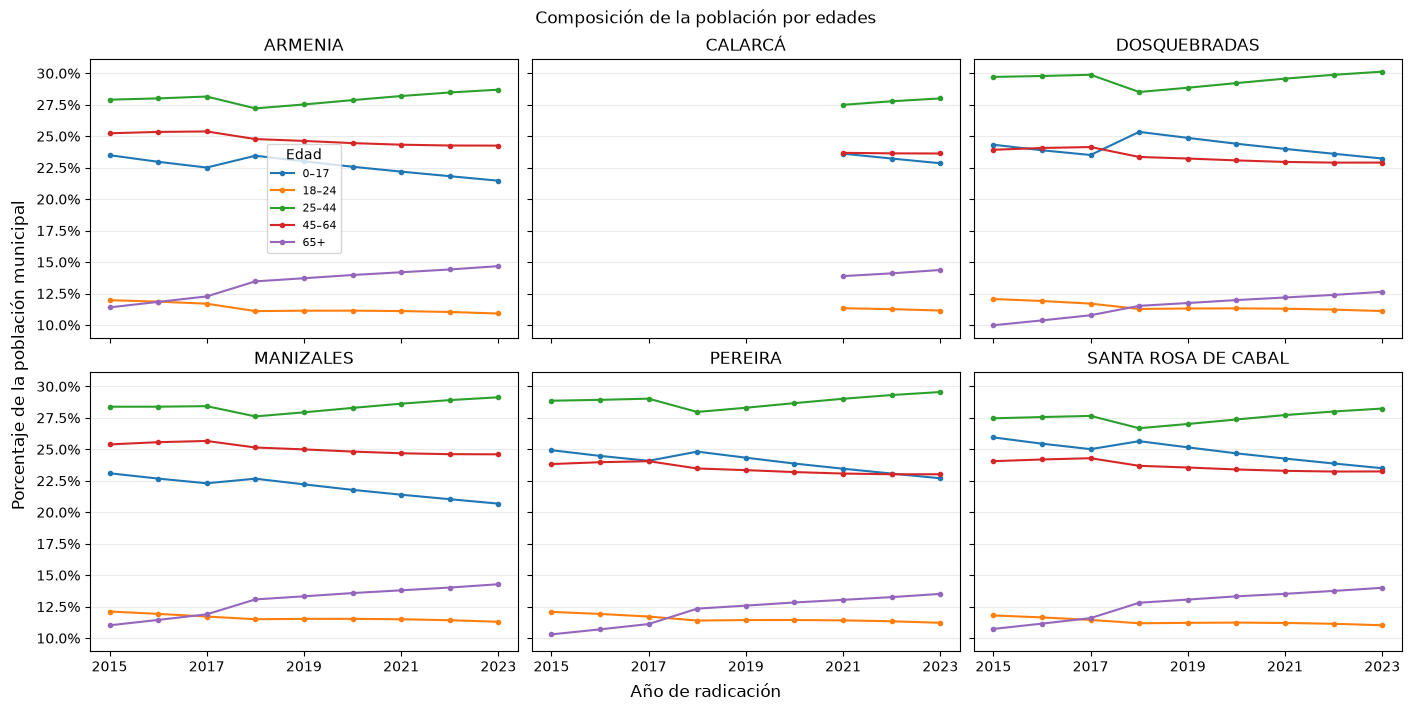

In [42]:
anios = range(2015, 2024)

fig, ejes = plt.subplots(
    2, 3, figsize=(14, 7), sharex=True, sharey=True, layout="constrained"
)

for ax, (municipio, grupo) in zip(ejes.flat, edades_anual.groupby("municipio")):
    serie = grupo.set_index("year_radica").reindex(anios)

    for rango in grupos_edad:
        ax.plot(serie.index, serie[rango], marker="o", markersize=3, label=rango)

    ax.set(title=municipio, xticks=[2015, 2017, 2019, 2021, 2023])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.grid(axis="y", alpha=0.25)

ejes[0, 0].legend(title="Edad", fontsize=8)
fig.suptitle("Composición de la población por edades")
fig.supxlabel("Año de radicación")
fig.supylabel("Porcentaje de la población municipal")
plt.show()

se calculó la proporción de población en cinco grupos de edad (0-17, 18-24, 25-44, 45-64 y 65+) para cada municipio y año. Se verificó que los conteos por edad sumaran la población municipal y que las cinco proporciones sumaran el 100%.

## Hallazgos
1. El grupo de 25 a 44 años tuvo la mayor participación en todos los municipios y años. En 2023 representó entre aproximadamente el 28% y 30% de la población municipal.
2. El grupo de 65 o más años ganó participación en los seis municipios. En Armenia pasó de aproximadamente 11% en 2015 a 15% aproximadamente en 2023.
3. El grupo de 0 a 17 años perdió participación entre el primer y últmo año observado en los seis municipios. En Manizales pasó de aproximadamente 23% en 2015 a 20% en 2023.
4. En varios municipios se observan cambios de nivel en 2018, especialmente el grupo de 25 a 44 años. Ese año coincide con el cambio de serie del DANE y debe tenerse en cuenta al interpretar la variación frente a 2017.

# Relación entre el valor de las compraventas y las variables del DANE

In [43]:
claves = ["municipio", "year_radica"]

relacion = resumen_anual.merge(
    dane_anual[claves + [
        "va_total_ajustado_ipc_2023",
        "elic_unidades_vivienda_nueva_lag1",
    ]],
    on=claves,
    how="left",
    validate="one_to_one",
)

poblacion = datos[claves + ["poblacion_total"]].drop_duplicates()
poblacion = poblacion.rename(columns={
    "year_radica": "anio_licencias",
    "poblacion_total": "poblacion_anio_licencias",
})

relacion["anio_licencias"] = relacion["year_radica"] - 1
relacion = relacion.merge(
    poblacion,
    on=["municipio", "anio_licencias"],
    how="left",
    validate="many_to_one",
)

denominador = relacion["poblacion_anio_licencias"]
relacion["viviendas_por_1000"] = (
    1000 * relacion["elic_unidades_vivienda_nueva_lag1"]
    / denominador.where(denominador.gt(0))
)

print("Combinaciones sin población del año de las licencias")
display(relacion.loc[
    denominador.isna(),
    ["municipio", "year_radica", "anio_licencias"],
])

Combinaciones sin población del año de las licencias


,municipio,year_radica,anio_licencias
0,ARMENIA,2015,2014
9,CALARCÁ,2021,2020
12,DOSQUEBRADAS,2015,2014
21,MANIZALES,2015,2014
30,PEREIRA,2015,2014
39,SANTA ROSA DE CABAL,2015,2014


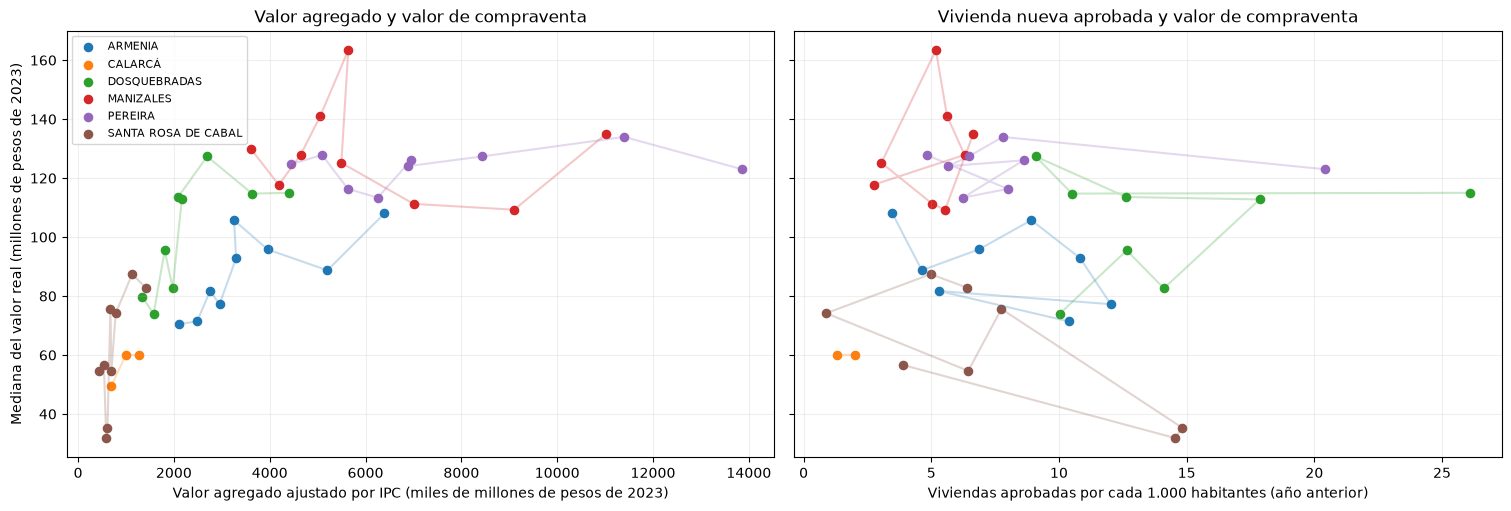

In [44]:
variables = {
    "va_total_ajustado_ipc_2023": (
        "Valor agregado y valor de compraventa",
        "Valor agregado ajustado por IPC (miles de millones de pesos de 2023)",
    ),
    "viviendas_por_1000": (
        "Vivienda nueva aprobada y valor de compraventa",
        "Viviendas aprobadas por cada 1.000 habitantes (año anterior)",
    ),
}

fig, ejes = plt.subplots(
    1, 2, figsize=(15, 5), sharey=True, layout="constrained"
)

for i, (municipio, grupo) in enumerate(relacion.groupby("municipio")):
    grupo = grupo.sort_values("year_radica")
    color = f"C{i}"

    for ax, (columna, _) in zip(ejes, variables.items()):
        ax.plot(
            grupo[columna], grupo["mediana_millones"],
            color=color, alpha=0.25,
        )
        ax.scatter(
            grupo[columna], grupo["mediana_millones"],
            color=color, label=municipio, s=35,
        )

for ax, (titulo, etiqueta) in zip(ejes, variables.values()):
    ax.set(title=titulo, xlabel=etiqueta)
    ax.grid(alpha=0.2)

ejes[0].set_ylabel("Mediana del valor real (millones de pesos de 2023)")
ejes[0].legend(fontsize=8)
plt.show()

Se comparó la mediana anual del valor real de las compraventas con dos variables municipales: el valor agregado del mimo año ajustado por IPC y las viviendas nuevas aprobadas el año anterior pr cada 1.000 habitantes. Para calcular la tasa de vivienda se utilizó la población del año de las aprobaciones. Cada punto representa un municipio y año de radicación, y las lineas conectan los puntos de cada municipio en orden cronológico.

## Hallazgos
1. Valor agregado. Pereira y Manizales se ubican entre los municipios con mayor valor agregado y maypores medianas de compraventa. Dentro de cada municipio, la relación es menos uniforme. En manizales, por ejemplo, la mediana alcanzó cerca de 164 millones de pesos en un año con un valor agregado inferior al de varios años posteriores.
2. Vivienda nueva aprobada. El gráfico no muestra una dirección común entre municipios. Dosquebradas alcanza su mayor tasa, cerca de 26 viviendas aprobadas por cada 1.000 habitantes, con una mediana cercana a 115 millones de pesos. Su mediana más alta, de unos 127 millones, se observa con una tasa de alrededor de 9 viviendas por cada 1.000 habitantes.
3. Cobertura. El gráfico de vivienda tiene menos observaciones porque el calculo requiere la población del año anterior. En la tabla hacen falta esos denominadores para los registros del 2015 y para Calarcá en 2021.

La relación visual con el valor agregado refleja diferencias entre municipios de distinto tamaño. Para saber si estas variables ayudan a predecir el valor de las compraventas, queda pendiente comparar el modelo base y el enriquecido.